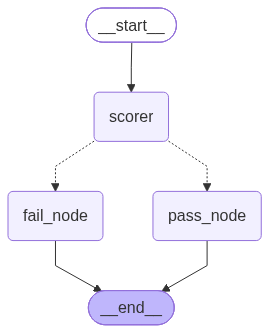

111

{'score': 111, 'result': '通过！'}

In [3]:
from typing import Literal, TypedDict

from IPython.core.display import Image
from langgraph.constants import END, START
from langgraph.graph import StateGraph
from rich import print as rich_print


# =================1. 定义State数据结构和Reducer=================
class RouteState(TypedDict):
    score: int
    result: str


# =================2. Node: 定义处理逻辑=================
def scorer(state: RouteState):
    score = int(input("请输入分数:"))
    rich_print(score)
    return {"score": score}  # 模拟评分


def pass_node(state: RouteState):
    return {"result": "通过！"}


def fail_node(state: RouteState):
    return {"result": "不通过"}


# =================3. 定义路由节点，决定下个Node=================
def router(state: RouteState) -> Literal["pass_node", "fail_node"]:
    if state["score"] >= 60:
        return "pass_node"
    else:
        return "fail_node"


# ===================3. 创建Graph===================
builder = StateGraph(RouteState)  # 3.1.注册State，初始化图Builder
# 3.2.注册节点
builder.add_node("scorer", scorer)
builder.add_node("pass_node", pass_node)
builder.add_node("fail_node", fail_node)
# 3.3.注册Edge，定义Node执行顺序
builder.add_edge(START, "scorer")
builder.add_conditional_edges("scorer", router)
builder.add_edge("pass_node", END)
builder.add_edge("fail_node", END)

graph = builder.compile()  # 3.4.编译成可执行图
display(Image(graph.get_graph(xray=True).draw_mermaid_png()))

# ===================4.调用graph======================
# 调用graph，传入初始的state，返回的是处理后的 state

# start(用户输入name) --> 节点1（生成问候语）--> 节点2（把问候语转大写）--> end
result = graph.invoke({})
rich_print(result)